# Часть 1: Реализация линейного SVM и функции потерь

### Задание 1.1: Реализация функции потерь Hinge Loss

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from collections import Counter
import math
from sklearn.svm import SVC
import random
import pandas as pd

def hinge_loss(y_true, y_scores):
    return np.maximum(0, 1 - y_true * y_scores)
    
def total_hinge_loss_with_reg(y_true, y_scores, w, C):
    hinge_losses_sum = np.sum(hinge_loss(y_true, y_scores))
    reg_term = 0.5 * np.dot(w, w)
    return C * hinge_losses_sum + reg_term

### Задание 1.2: Реализация линейного SVM с мягким зазором (Soft-Margin)

In [68]:
class MyLinearSVM:
    def __init__(self):
        self.w = None      # Вектор весов
        self.b = None      # Смещение
        self.loss_history = []

    def fit(self, X_train, y_train, C=1.0, learning_rate=0.01, epochs=1000):
        X_train = np.asarray(X_train, dtype=float)
        y_train = np.asarray(y_train, dtype=float)
        n_samples, n_features = X_train.shape

        self.w = np.zeros(n_features)
        self.b = 0.0

        # Метки в формат +1 / -1
        y_train = np.where(y_train <= 0, -1.0, 1.0)

        self.loss_history = []

        for epoch in range(epochs):
            indices = np.random.permutation(n_samples)
            X_sh = X_train[indices]
            y_sh = y_train[indices]

            for xi, yi in zip(X_sh, y_sh):
                # score = <w, x> + b 
                score = np.dot(xi, self.w) + self.b
                margin = yi * score

                if margin >= 1:
                    # Субградиент: (w, 0)
                    self.w -= learning_rate * self.w
                else:
                    # Субградиент: (w - C*y*x, -C*y)
                    self.w -= learning_rate * (self.w - C * yi * xi)
                    self.b -= learning_rate * (-C * yi)   # = + lr*C*yi

            scores_all = X_train @ self.w + self.b
            loss = total_hinge_loss_with_reg(y_train, scores_all, self.w, C)
            self.loss_history.append(loss)

        return self

    def decision_function(self, X_test):
        X_test = np.asarray(X_test, dtype=float)
        return X_test @ self.w + self.b        # w·x + b

    def predict(self, X_test):
        scores = self.decision_function(X_test)
        return np.where(scores >= 0, 1, -1)

class MyKernelSVM:
    def __init__(self, gamma=1.0):
        self.gamma = gamma
        self.alpha = None
        self.b = None
        self.X_train = None
        self.y_train = None

    def _rbf_kernel(self, X1, X2):
        X1 = np.array(X1)
        X2 = np.array(X2)
        if X1.ndim == 1: X1 = X1[np.newaxis, :]
        if X2.ndim == 1: X2 = X2[np.newaxis, :]
        
        dists = np.sum(X1**2, axis=1)[:, np.newaxis] + np.sum(X2**2, axis=1) - 2 * np.dot(X1, X2.T)
        dists = np.maximum(dists, 0)
        return np.exp(-self.gamma * dists)

    def fit(self, X_train, y_train, C=1.0, learning_rate=0.005, epochs=1500):
        """Обучение Ядерного SVM с использованием hinge_loss для вычисления субградиента"""
        self.X_train = np.array(X_train)
        self.y_train = np.where(np.array(y_train) <= 0, -1, 1)
        n_samples = self.X_train.shape[0]
        
        self.alpha = np.zeros(n_samples)
        self.b = 0.0
        
        K = self._rbf_kernel(self.X_train, self.X_train)
        
        for epoch in range(epochs):
            for i in range(n_samples):
                # Вычисляем "сырой" скор f(x_i)
                score = np.sum(self.alpha * self.y_train * K[:, i]) - self.b
                
                loss = hinge_loss(self.y_train[i], score)
                
                if loss > 0:
                    self.alpha[i] += learning_rate * C
                    self.b -= learning_rate * C * self.y_train[i]
            
            self.alpha = np.clip(self.alpha, 0, C)

    def decision_function(self, X):
        X = np.array(X)
        K = self._rbf_kernel(self.X_train, X)
        return np.dot(self.alpha * self.y_train, K) - self.b

    def predict(self, X):
        scores = self.decision_function(X)
        return np.where(scores >= 0, 1, -1)

### Задание 1.3: Исследование параметра C и визуализация

--- Результаты метрик ---
C =  0.1 | Accuracy: 0.578 | Precision: 0.578 | Recall: 1.000
C =  1.0 | Accuracy: 1.000 | Precision: 1.000 | Recall: 1.000
C = 10.0 | Accuracy: 1.000 | Precision: 1.000 | Recall: 1.000


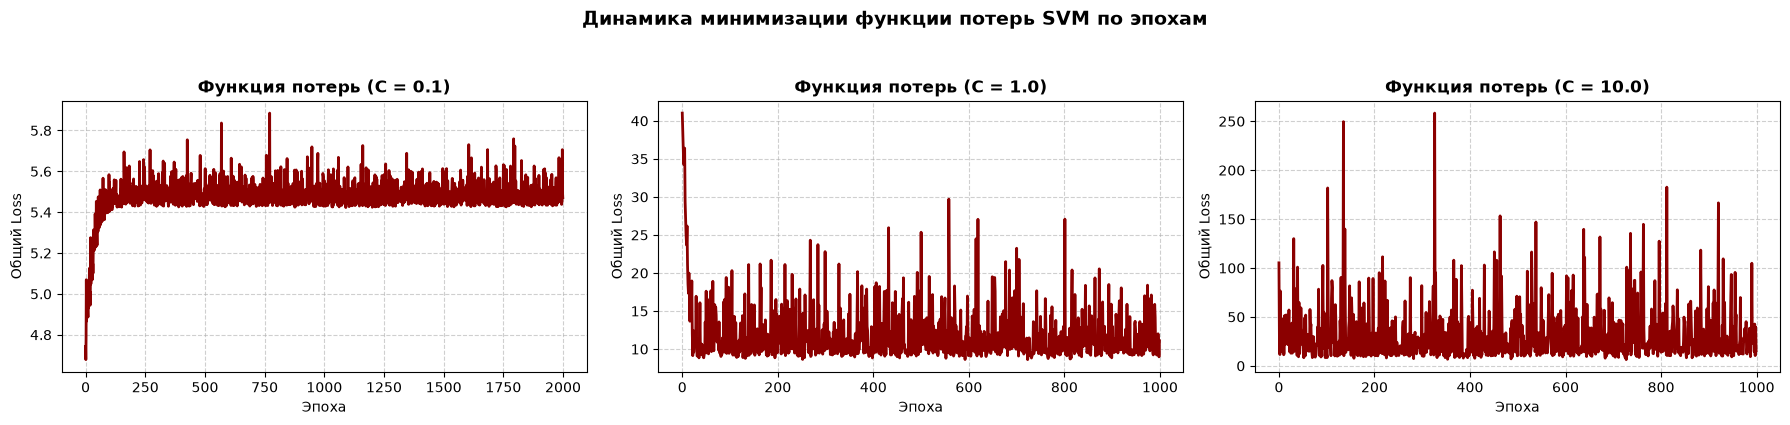

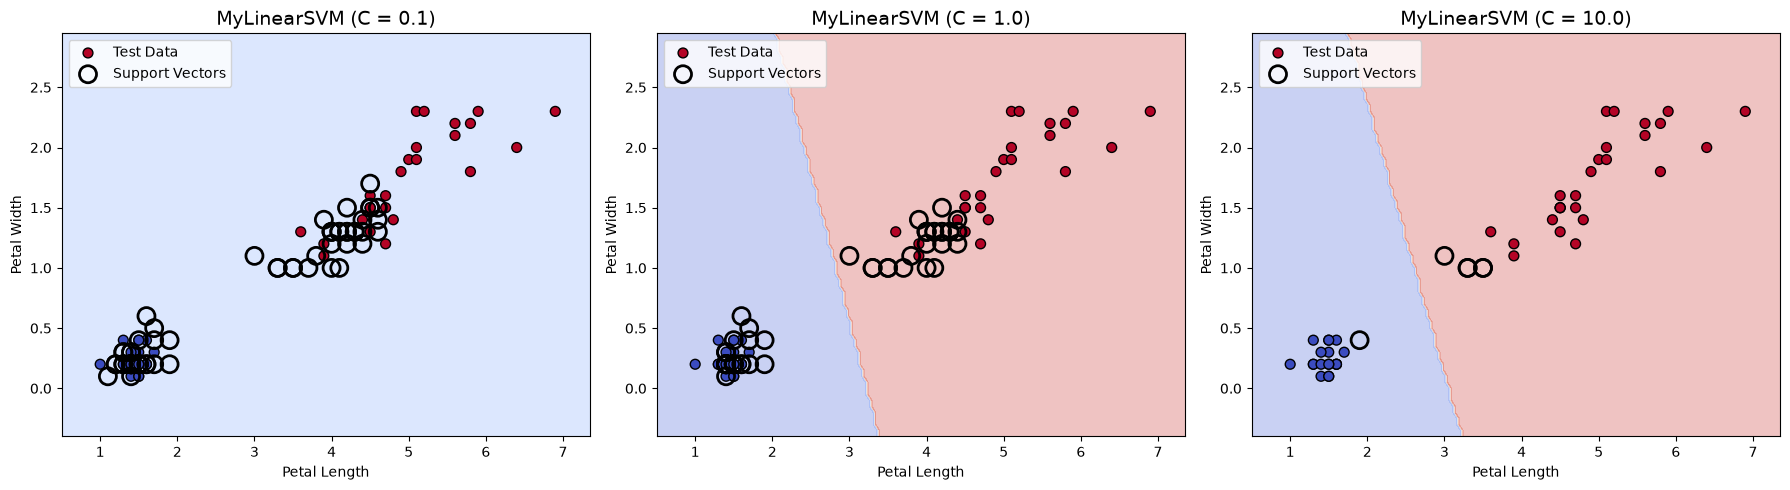

In [69]:
iris = load_iris()
# Берем только 2 признака для визуализации: Petal Length и Petal Width
X = iris.data[:, 2:] 
y = iris.target

# Преобразуем в бинарную задачу: setosa (класс 0) против остальных (классы 1 и 2)
# setosa = -1, остальные = 1
y_binary = np.where(y == 0, -1, 1)

# Разделяем на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y_binary, test_size=0.3, random_state=42
)

# Обучение моделей с разными значениями C
C_values = [0.1, 1.0, 10.0]
models = {}

print("--- Результаты метрик ---")
for C in C_values:
    svm = MyLinearSVM()
    # Увеличим количество эпох для малых C, чтобы модель успела сойтись
    epochs = 2000 if C < 1 else 1000 
    svm.fit(X_train, y_train, C=C, learning_rate=0.01, epochs=epochs)
    models[C] = svm
    
    y_pred = svm.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='binary', pos_label=1)
    rec = recall_score(y_test, y_pred, average='binary', pos_label=1)
    
    print(f"C = {C:4} | Accuracy: {acc:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f}")

fig_loss, axes_loss = plt.subplots(1, 3, figsize=(18, 4))

for i, C in enumerate(C_values):
    ax_loss = axes_loss[i]
    svm = models[C]
    
    # Отрисовываем историю лоссов, сохраненную во время fit()
    if hasattr(svm, 'loss_history'):
        ax_loss.plot(svm.loss_history, color='darkred', linewidth=2)
        ax_loss.set_title(f'Функция потерь (C = {C})', fontsize=12, weight='bold')
        ax_loss.set_xlabel('Эпоха')
        ax_loss.set_ylabel('Общий Loss')
        ax_loss.grid(True, linestyle='--', alpha=0.6)
    else:
        ax_loss.text(0.5, 0.5, "История потерь\nне найдена в модели", 
                     ha='center', va='center', color='red')
        
plt.suptitle("Динамика минимизации функции потерь SVM по эпохам", fontsize=14, weight='bold', y=1.05)
plt.tight_layout()
plt.show()

# Визуализация решающих границ и опорных векторов
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, C in enumerate(C_values):
    ax = axes[i]
    svm = models[C]
    
    # Создаем сетку для отрисовки решающей границы
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                         np.arange(y_min, y_max, 0.05))
    
    # Предсказываем классы для каждой точки сетки
    Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Рисуем фон (решающую границу)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    
    # Рисуем тестовые точки
    scatter = ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', 
                         edgecolors='k', s=50, label='Test Data')
    
    # Находим и рисуем опорные векторы на обучающей выборке
    # Опорные векторы в soft-margin SVM - это точки, для которых |score| <= 1
    train_scores = svm.decision_function(X_train)
    sv_mask = np.abs(train_scores) <= 1.0
    
    if np.any(sv_mask):
        ax.scatter(X_train[sv_mask, 0], X_train[sv_mask, 1], s=150, linewidth=2,
                   facecolors='none', edgecolors='black', label='Support Vectors')
        
    ax.set_title(f'MyLinearSVM (C = {C})', fontsize=14)
    ax.set_xlabel('Petal Length')
    ax.set_ylabel('Petal Width')
    ax.legend(loc='upper left')
    
plt.tight_layout()
plt.show()

# Часть 2: Реализация деревьев решений

### Задание 2.1: Реализация критериев разделения

In [70]:
def gini_impurity(y):
    n_samples = len(y)
    if n_samples == 0:
        return 0

    counts = Counter(y)
    summary = 0
    for count in counts.values():
        summary += (count/n_samples)**2

    return 1 - summary


def entropy(y):
    n_samples = len(y)
    if n_samples == 0:
        return 0

    counts = Counter(y)
    summary = 0
    for count in counts.values():
        summary += (count/n_samples) * math.log2(count/n_samples)

    return -summary


def information_gain(parent_impurity, children_impurities, children_sizes):
    total_size = sum(children_sizes)
    if total_size == 0:
        return 0
        
    weighted_children_impurity = 0
    for impurity, size in zip(children_impurities, children_sizes):
        weighted_children_impurity += (size/total_size) * impurity

    return parent_impurity - weighted_children_impurity

### Задание 2.2: Реализация алгоритма построения дерева (CART/ID3)

In [71]:
# класс дерева
class MyDecisionTreeClassifier:
    
    # класс узла
    class Node:
        def __init__(self, feature=None, threshold=None, left=None, right=None, value=None):
            self.feature = feature
            self.threshold = threshold
            self.left = left
            self.right = right
            self.value = value
            
        @property
        def is_leaf(self):
            return self.value is not None
            
            
    # метод расчета порогов
    def __get_thresholds(self, values):
        unique_values = sorted(list(set(values)))
        thresholds = list()
        for i in range(len(unique_values) - 1):
            median = (unique_values[i] + unique_values[i+1]) / 2
            thresholds.append(median)
        return thresholds

    
    # вспомогательный метод выбора критерия
    def __get_impurity(self, y):
        if self.criterion == 'gini':
            return gini_impurity(y)
        elif self.criterion == 'entropy':
            return entropy(y)
        return 0
        

    # метод поиска наилучшего разбиения
    def __find_best_split(self, X, y):
        best_gain = -1
        split_idx, split_threshold = None, None

        n_samples = len(X)
        if n_samples == 0:
            return None, None

        n_features = len(X[0])
        parent_impurity = self.__get_impurity(y)

        if self.max_features is None or self.max_features >= n_features:
            feature_indices = range(n_features)
        else:
            feature_indices = random.sample(range(n_features), self.max_features)

        # перебираем все признаки
        for feat_idx in feature_indices:
            feature_values = [row[feat_idx] for row in X]
            thresholds = self.__get_thresholds(feature_values)

            # перебираем все пороги
            for threshold in thresholds:
                left_y = [y[i] for i in range(n_samples) if X[i][feat_idx] <= threshold]
                right_y = [y[i] for i in range(n_samples) if X[i][feat_idx] > threshold]

                if len(left_y) == 0 or len(right_y) == 0:
                    continue

                # считаем прирост информации
                gain = information_gain(parent_impurity, [self.__get_impurity(left_y), self.__get_impurity(right_y)], [len(left_y), len(right_y)])

                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_threshold = threshold

        return split_idx, split_threshold
        
    
    # метод построения дерева
    def __build_tree(self, X, y, depth=0):
        n_samples = len(X)
        n_classes = len(set(y))

        # определяем базовый класс для листа
        most_common_class = Counter(y).most_common(1)[0][0] if n_samples > 0 else None

        # проверяем критерии остановки
        if (n_classes == 1 or 
            (self.max_depth is not None and depth >= self.max_depth) or
            n_samples < self.min_samples_split):
            return self.Node(value=most_common_class)

        # ищем лучшее разбиение
        best_feature, best_threshold = self.__find_best_split(X, y)

        if best_feature is None:
            return self.Node(value=most_common_class)

        # Разделяем обучающую выборку на лево (<= threshold) и право (> threshold)
        left_idx = [i for i in range(n_samples) if X[i][best_feature] <= best_threshold]
        right_idx = [i for i in range(n_samples) if X[i][best_feature] > best_threshold]
        
        X_left = [X[i] for i in left_idx]
        y_left = [y[i] for i in left_idx]
        
        X_right = [X[i] for i in right_idx]
        y_right = [y[i] for i in right_idx]

        # Рекурсивно строим поддеревья, увеличивая текущую глубину на 1
        left_child = self.__build_tree(X_left, y_left, depth + 1)
        right_child = self.__build_tree(X_right, y_right, depth + 1)
        
        return self.Node(feature=best_feature, threshold=best_threshold, left=left_child, right=right_child)
        

    # метод обучения дерева
    def fit(self, X_train, y_train, criterion='gini', max_depth=None, min_samples_split=2, max_features=None):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.root = self.__build_tree(X_train, y_train)
        return self

    
    # метод рекурсивного спуска для строки
    def __predict_row(self, node, row):
        if node.is_leaf:
            return node.value

        if row[node.feature] <= node.threshold:
            return self.__predict_row(node.left, row)
        else:
            return self.__predict_row(node.right, row)

    
    # метод предсказания
    def predict(self, X_test):
        if self.root is None:
            raise ValueError("Дерево еще не обучено! Сначала вызовите метод fit()")
        return [self.__predict_row(self.root, row) for row in X_test]

### Задание 2.3: Визуализация дерева и анализ переобучения


 АНАЛИЗ ДЕРЕВА С MAX_DEPTH = 1


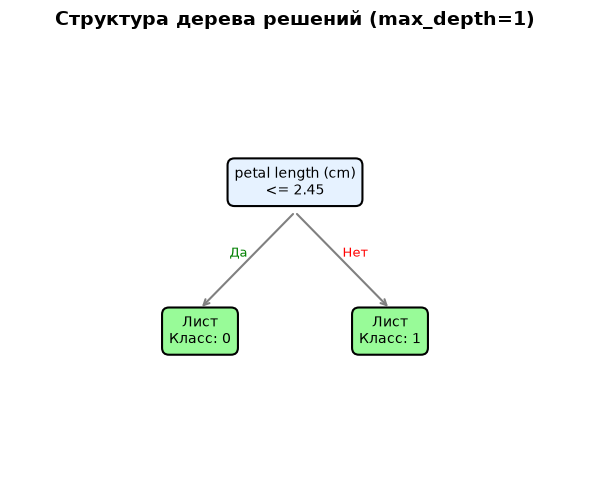


Accuracy на TRAIN: 0.6667
Accuracy на TEST:  0.6667

 АНАЛИЗ ДЕРЕВА С MAX_DEPTH = 3


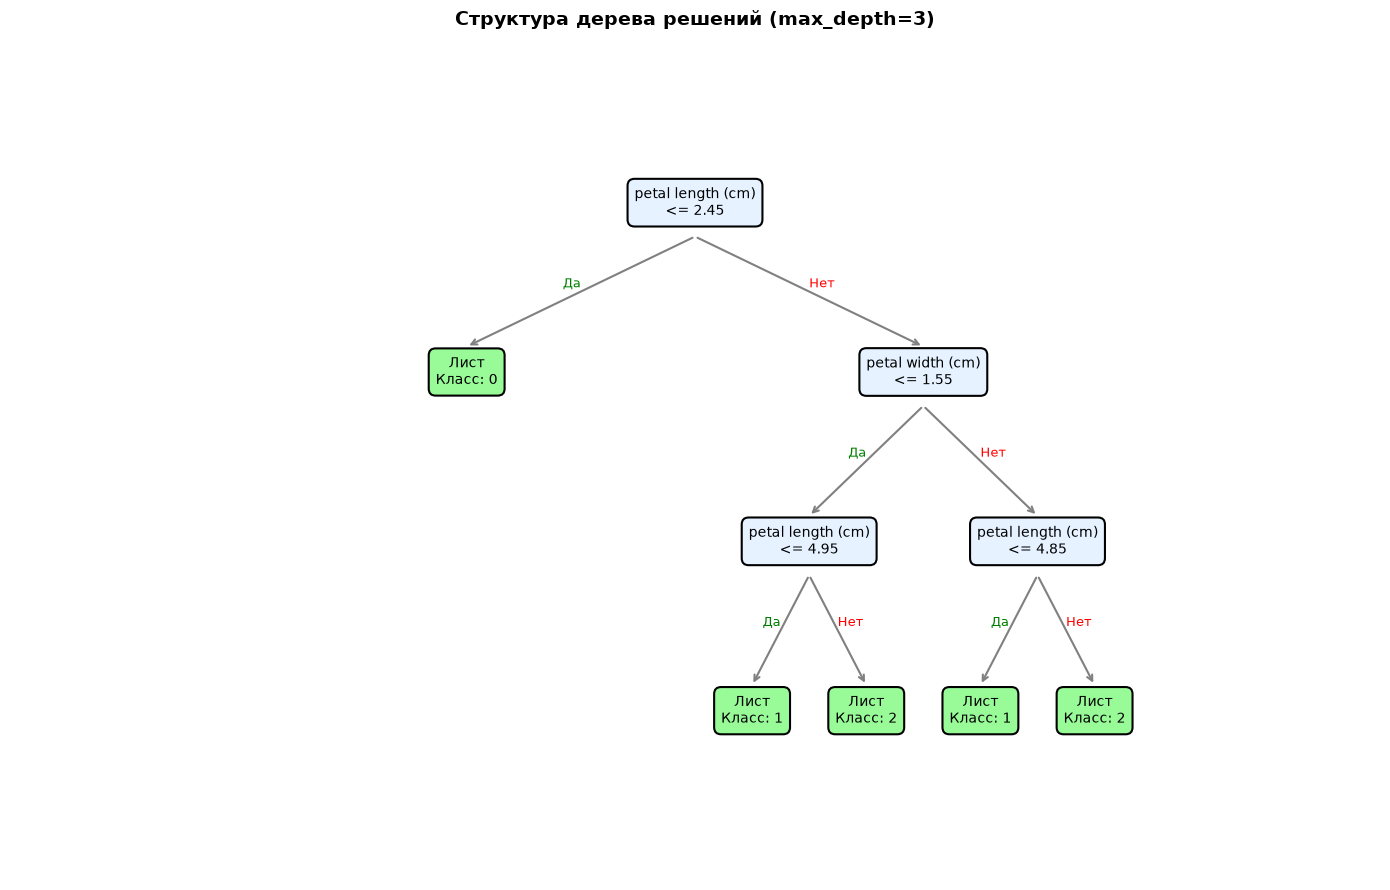


Accuracy на TRAIN: 0.9810
Accuracy на TEST:  0.9333

 АНАЛИЗ ДЕРЕВА С MAX_DEPTH = None


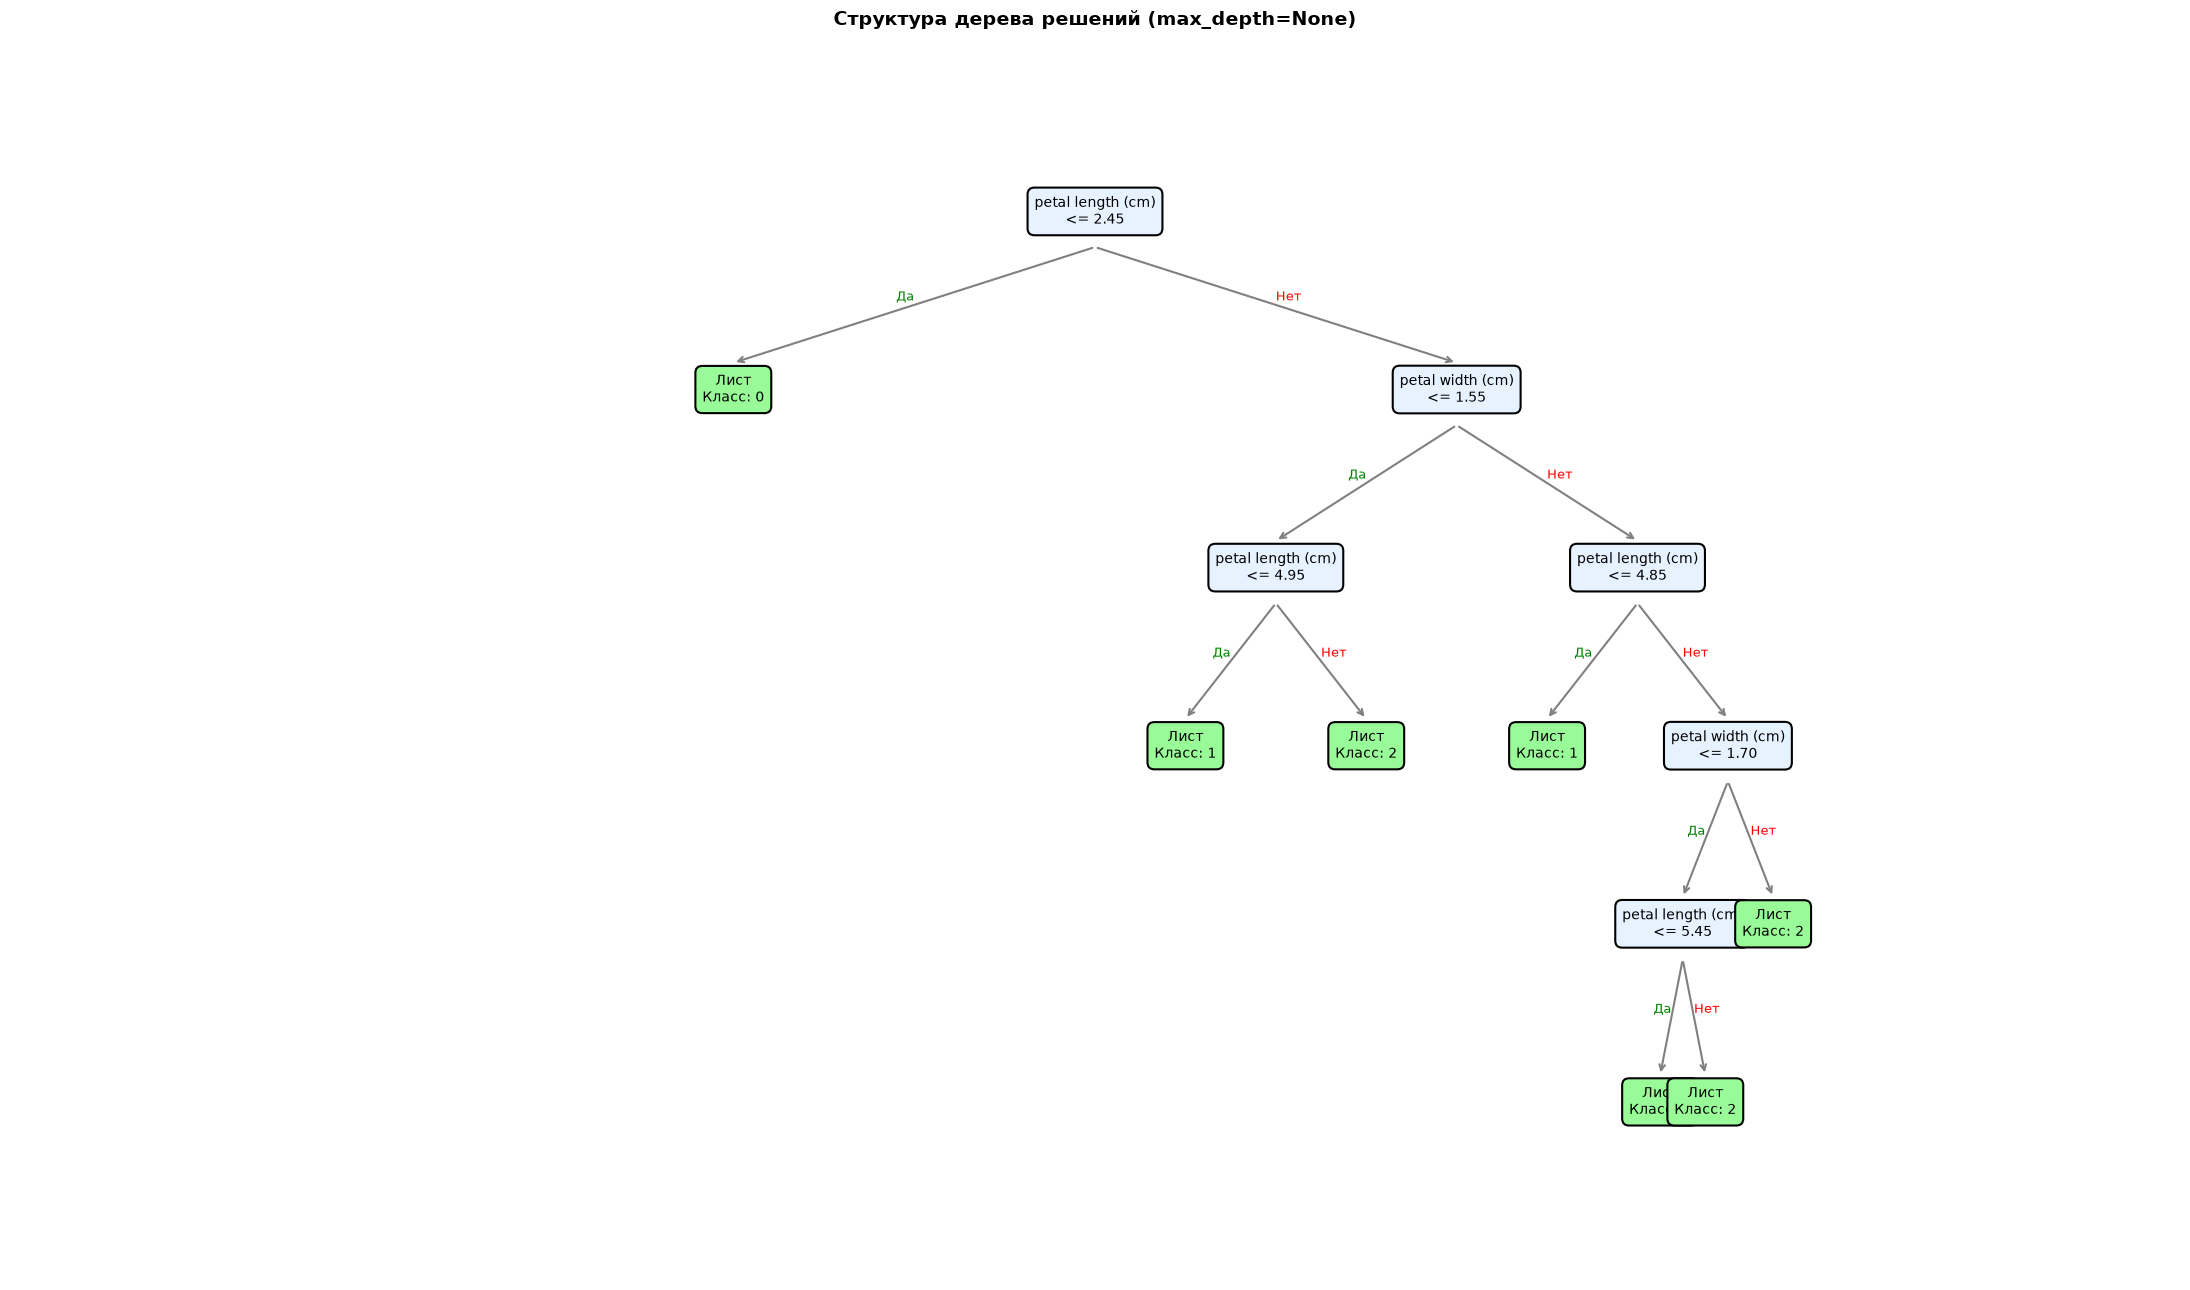


Accuracy на TRAIN: 0.9905
Accuracy на TEST:  0.9556


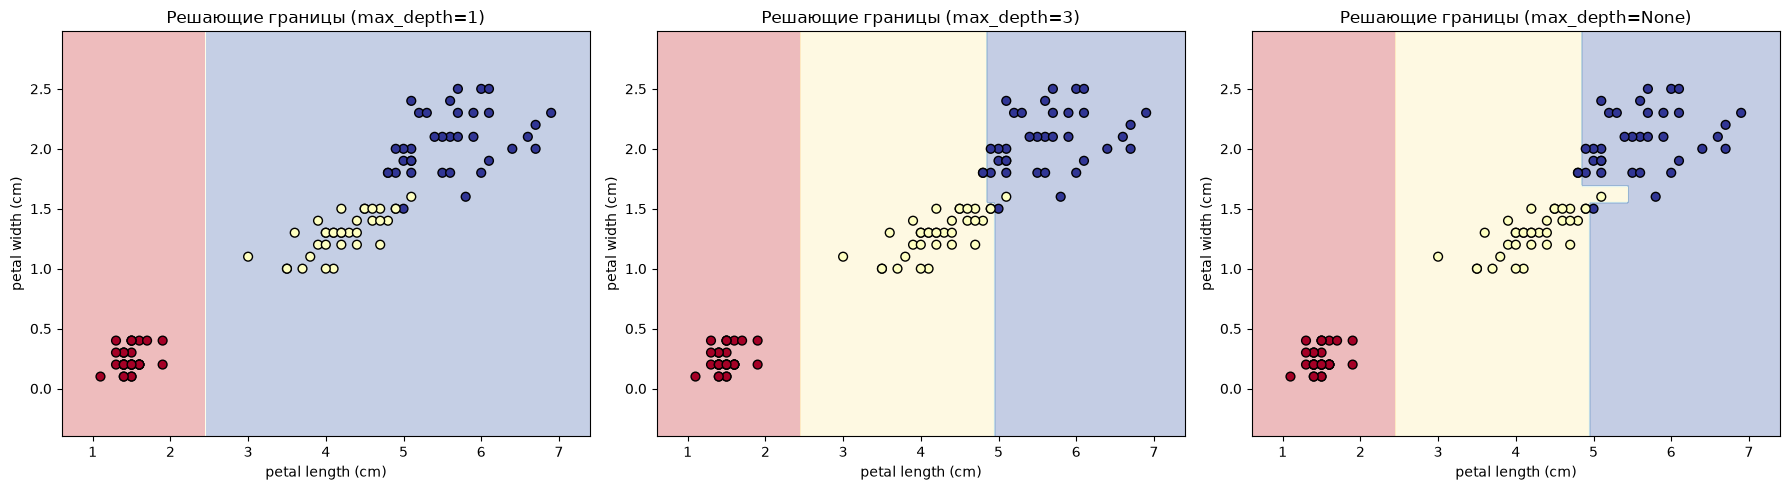

In [72]:
class TreeVisualizer:
    def __init__(self, feature_names=None):
        self.feature_names = feature_names

    def _get_tree_depth(self, node):
        """Вычисляет фактическую глубину дерева."""
        # Исправлено: обращение к свойству is_leaf без скобок
        if node is None or node.is_leaf:  
            return 0
        return 1 + max(self._get_tree_depth(node.left), self._get_tree_depth(node.right))

    def _plot_node(self, node, x, y, dx, depth, ax):
        if node is None:
            return

        node_style = dict(boxstyle="round,pad=0.5", ec="black", lw=1.5)
        
        # Исправлено: обращение к свойству is_leaf без скобок
        if node.is_leaf:  
            class_val = node.value if node.value is not None else "Unknown"
            ax.text(x, y, f"Лист\nКласс: {class_val}", ha="center", va="center",
                    bbox=dict(**node_style, fc="#98fb98")) # Зеленый цвет для листьев
            return

        feat_name = self.feature_names[node.feature] if self.feature_names else f"X[{node.feature}]"
        node_text = f"{feat_name}\n<= {node.threshold:.2f}"
        
        ax.text(x, y, node_text, ha="center", va="center",
                bbox=dict(**node_style, fc="#e6f2ff")) # Голубой цвет для развилок

        y_child = y - 1.0
        x_left = x - dx / (2 ** depth)
        x_right = x + dx / (2 ** depth)

        if node.left:
            ax.annotate("", xy=(x_left, y_child + 0.15), xytext=(x, y - 0.2),
                        arrowprops=dict(arrowstyle="->", color="gray", lw=1.5))
            ax.text((x + x_left)/2, (y + y_child)/2, "Да", color="green", fontsize=9, ha="right")
            self._plot_node(node.left, x_left, y_child, dx, depth + 1, ax)

        if node.right:
            ax.annotate("", xy=(x_right, y_child + 0.15), xytext=(x, y - 0.2),
                        arrowprops=dict(arrowstyle="->", color="gray", lw=1.5))
            ax.text((x + x_right)/2, (y + y_child)/2, "Нет", color="red", fontsize=9, ha="left")
            self._plot_node(node.right, x_right, y_child, dx, depth + 1, ax)

    def draw(self, my_tree):
        """Отрисовывает структуру переданного дерева."""
        if my_tree.root is None:
            print("Дерево не обучено!")
            return

        max_d = self._get_tree_depth(my_tree.root)
        
        fig, ax = plt.subplots(figsize=(max_d * 4 + 2, max_d * 2 + 3))
        ax.axis('off')

        start_x = 0.0
        start_y = 10.0
        initial_dx = 4.0 

        self._plot_node(my_tree.root, start_x, start_y, initial_dx, 1, ax)
        
        ax.set_ylim(start_y - max_d - 1, start_y + 1)
        ax.set_xlim(-initial_dx * 1.5, initial_dx * 1.5)
        
        plt.title(f"Структура дерева решений (max_depth={my_tree.max_depth})", fontsize=14, weight='bold')
        plt.tight_layout()
        plt.show()

iris = load_iris()
X = iris.data[:, [2, 3]].tolist() 
y = iris.target.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
feature_names = [iris.feature_names[2], iris.feature_names[3]]

depths = [1, 3, None]
models = {}

for depth in depths:
    print(f"\n" + "="*50)
    print(f" АНАЛИЗ ДЕРЕВА С MAX_DEPTH = {depth}")
    print("="*50)
    
    # Обучение
    tree = MyDecisionTreeClassifier()
    tree.fit(X_train, y_train, criterion='gini', max_depth=depth, min_samples_split=2)
    models[depth] = tree
    
    # Визуализация структуры
    viz = TreeVisualizer(feature_names=feature_names)
    viz.draw(models[depth])
    
    # Сравнение точности
    train_preds = tree.predict(X_train)
    test_preds = tree.predict(X_test)
    
    train_acc = accuracy_score(y_train, train_preds)
    test_acc = accuracy_score(y_test, test_preds)
    
    print(f"\nAccuracy на TRAIN: {train_acc:.4f}")
    print(f"Accuracy на TEST:  {test_acc:.4f}")

X_train_np = np.array(X_train)
y_train_np = np.array(y_train)

# Настройка сетки для отрисовки разделяющих поверхностей
x_min, x_max = X_train_np[:, 0].min() - 0.5, X_train_np[:, 0].max() + 0.5
y_min, y_max = X_train_np[:, 1].min() - 0.5, X_train_np[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, depth in zip(axes, depths):
    tree = models[depth]
    
    # Предсказание сетки точек
    mesh_points = np.c_[xx.ravel(), yy.ravel()].tolist()
    Z = np.array(tree.predict(mesh_points))
    Z = Z.reshape(xx.shape)
    
    # Отрисовка цветных зон
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.RdYlBu)
    
    # Отображение обучающих точек
    scatter = ax.scatter(X_train_np[:, 0], X_train_np[:, 1], c=y_train_np, 
                         cmap=plt.cm.RdYlBu, edgecolor='black', s=40)
    
    ax.set_title(f"Решающие границы (max_depth={depth})")
    ax.set_xlabel(feature_names[0])
    ax.set_ylabel(feature_names[1])

plt.tight_layout()
plt.show()

# Часть 3: Сравнительный анализ SVM и Деревьев Решений

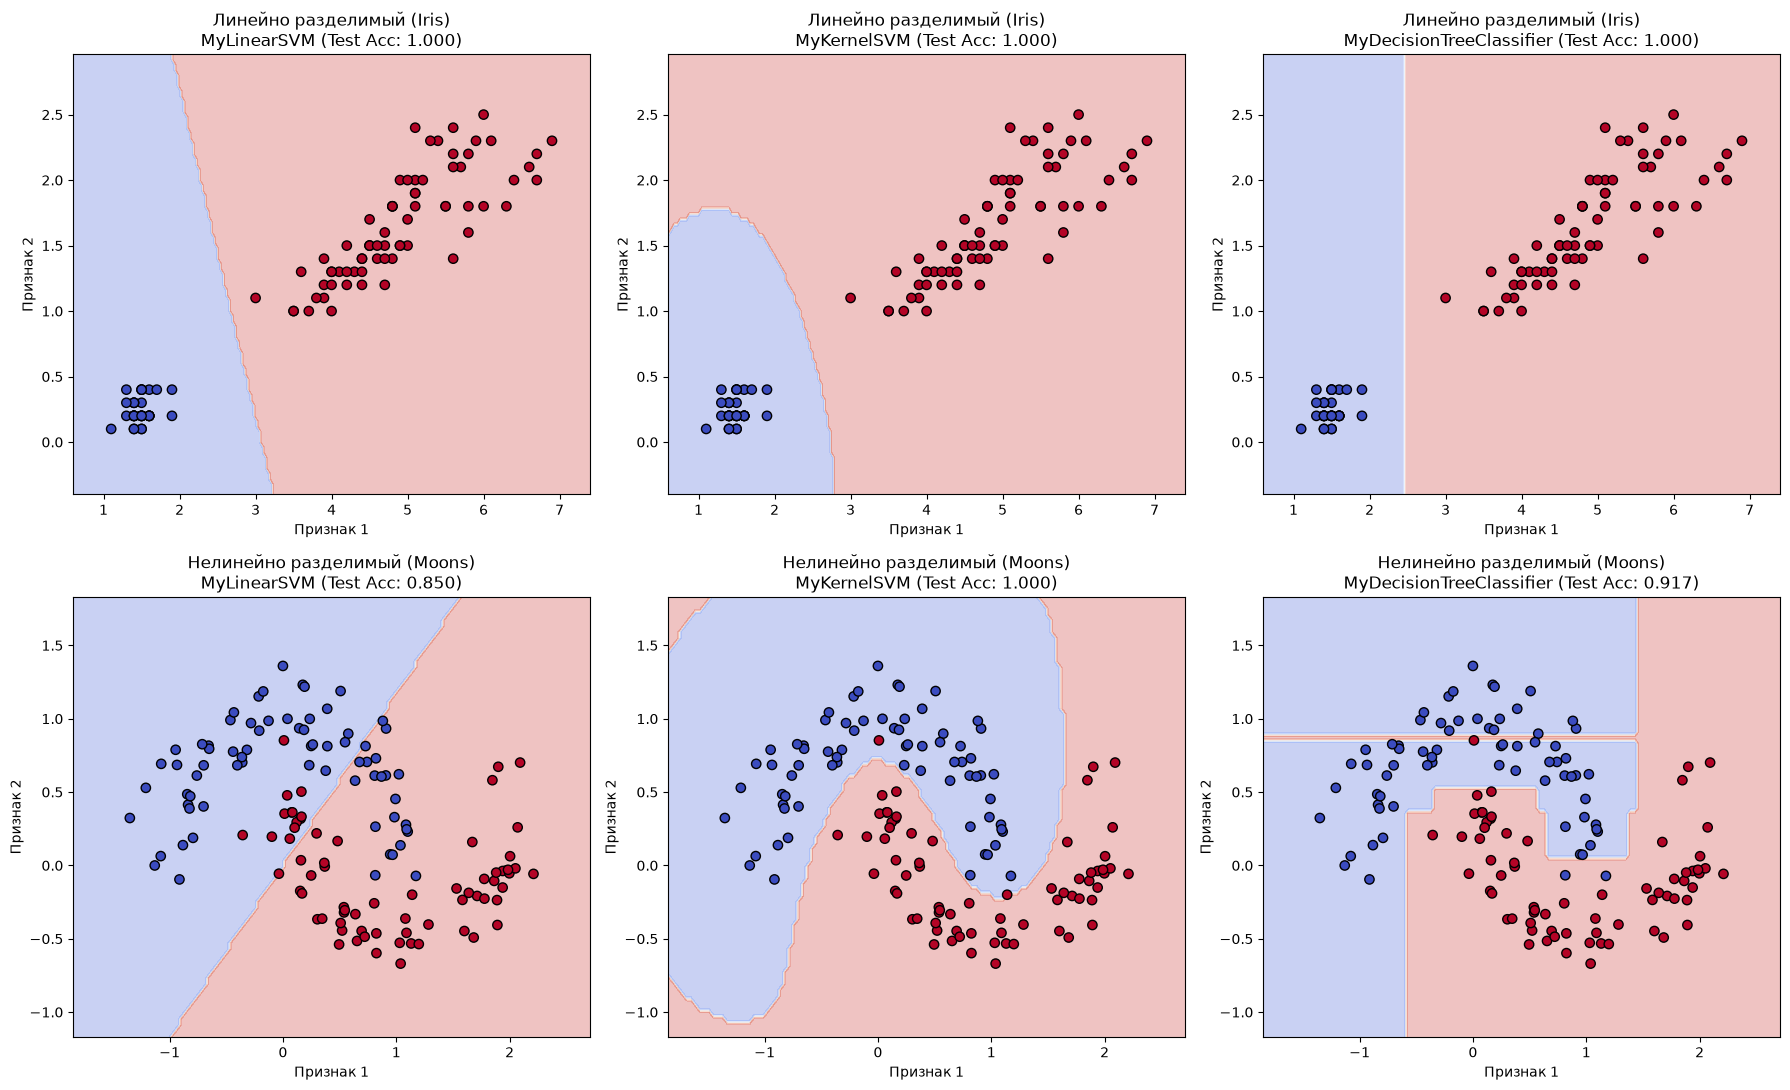


Данные: Линейно разделимый (Iris)
 - MyLinearSVM                        : 1.0000
 - MyKernelSVM                        : 1.0000
 - MyDecisionTreeClassifier           : 1.0000

Данные: Нелинейно разделимый (Moons)
 - MyLinearSVM                        : 0.8500
 - MyKernelSVM                        : 1.0000
 - MyDecisionTreeClassifier           : 0.9167


In [73]:
iris = load_iris()
X_iris = iris.data[:, [2, 3]].tolist() 
y_iris = np.where(iris.target == 0, -1, 1).tolist() 
X_train_lin, X_test_lin, y_train_lin, y_test_lin = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42, stratify=y_iris
)

X_moons, y_moons = make_moons(n_samples=200, noise=0.15, random_state=42)
y_moons = np.where(y_moons == 0, -1, 1).tolist()
X_train_nl, X_test_nl, y_train_nl, y_test_nl = train_test_split(
    X_moons.tolist(), y_moons, test_size=0.3, random_state=42, stratify=y_moons
)

datasets = {
    "Линейно разделимый (Iris)": (X_train_lin, X_test_lin, y_train_lin, y_test_lin),
    "Нелинейно разделимый (Moons)": (X_train_nl, X_test_nl, y_train_nl, y_test_nl)
}

params = {
    "Линейно разделимый (Iris)": {"C_lin": 1.0, "C_rbf": 1.0, "gamma": 0.5, "depth": 2},
    "Нелинейно разделимый (Moons)": {"C_lin": 0.1, "C_rbf": 10.0, "gamma": 1.5, "depth": 5}
}

results = {}
trained_models_dict = {}

for name, (X_tr, X_te, y_tr, y_te) in datasets.items():
    p = params[name]
    results[name] = {}
    
    svm_lin = MyLinearSVM()
    svm_lin.fit(X_tr, y_tr, C=p["C_lin"], learning_rate=0.01, epochs=1000)
    acc_svm_lin = accuracy_score(y_te, svm_lin.predict(X_te))
    results[name]["MyLinearSVM"] = acc_svm_lin
    
    svm_rbf = MyKernelSVM(gamma=p["gamma"]) 
    svm_rbf.fit(X_tr, y_tr, C=p["C_rbf"], learning_rate=0.01, epochs=1000)
    acc_svm_rbf = accuracy_score(y_te, svm_rbf.predict(X_te))
    results[name]["MyKernelSVM"] = acc_svm_rbf
    
    tree = MyDecisionTreeClassifier()
    tree.fit(X_tr, y_tr, criterion='gini', max_depth=p["depth"], min_samples_split=2)
    acc_tree = accuracy_score(y_te, tree.predict(X_te))
    results[name]["MyDecisionTreeClassifier"] = acc_tree
    
    trained_models_dict[name] = [svm_lin, svm_rbf, tree]


fig, axes = plt.subplots(2, 3, figsize=(18, 11))
plot_idx = 0

for name, (X_tr, X_te, y_tr, y_te) in datasets.items():
    p = params[name]
    X_tr_np = np.array(X_tr)
    y_tr_np = np.array(y_tr)
    
    # Построение сетки для отрисовки границ решений
    x_min, x_max = X_tr_np[:, 0].min() - 0.5, X_tr_np[:, 0].max() + 0.5
    y_min, y_max = X_tr_np[:, 1].min() - 0.5, X_tr_np[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.04), np.arange(y_min, y_max, 0.04))
    mesh_points = np.c_[xx.ravel(), yy.ravel()].tolist()
    
    # Берем уже обученные модели из словаря
    trained_models = trained_models_dict[name]
    model_keys = ["MyLinearSVM", "MyKernelSVM", "MyDecisionTreeClassifier"]
    
    for i, model in enumerate(trained_models):
        ax = axes[plot_idx, i]
        
        # Предсказания для всей сетки
        Z = np.array(model.predict(mesh_points)).reshape(xx.shape)
        
        # Отрисовка разделяющих зон
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
        # Отрисовка точек обучающей выборки
        ax.scatter(X_tr_np[:, 0], X_tr_np[:, 1], c=y_tr_np, cmap=plt.cm.coolwarm, edgecolor='k', s=45)
        
        acc = results[name][model_keys[i]]
        ax.set_title(f"{name}\n{model_keys[i]} (Test Acc: {acc:.3f})")
        ax.set_xlabel("Признак 1")
        ax.set_ylabel("Признак 2")
        
    plot_idx += 1

plt.tight_layout()
plt.show()

for dataset_name, models_data in results.items():
    print(f"\nДанные: {dataset_name}")
    for model_name, score in models_data.items():
        print(f" - {model_name:<35}: {score:.4f}")

# Часть 4: Введение в случайный лес (Random Forest)

                      mean     std     min     max
Дерево              0.8838  0.0227  0.8417  0.9250
Random Forest       0.9117  0.0224  0.8583  0.9417


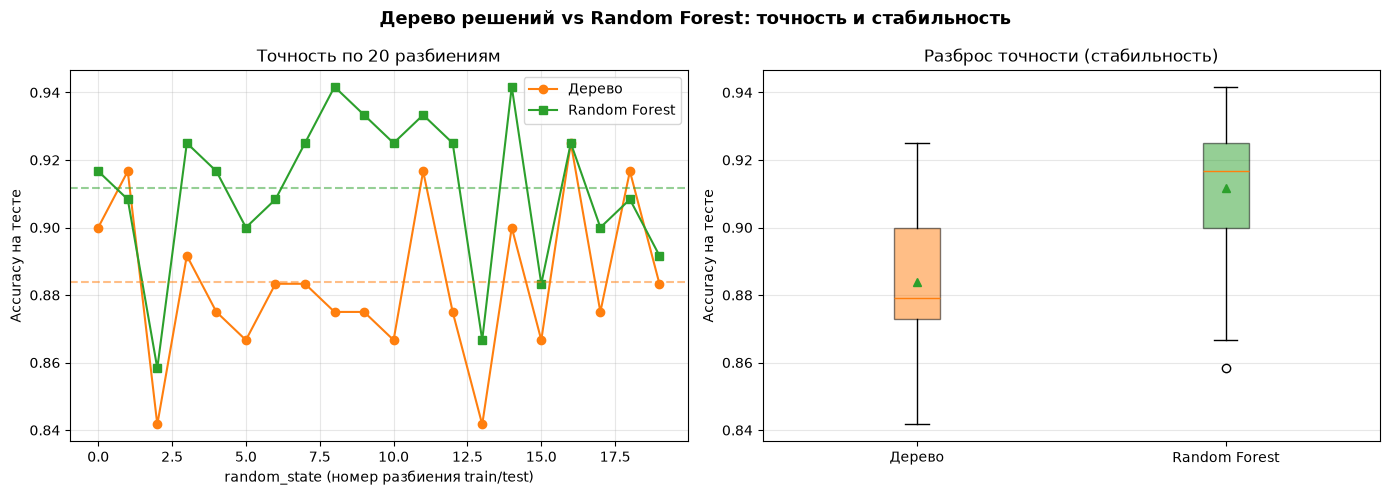

In [77]:
class MyRandomForestClassifier():
    
    def __init__(self, random_state=None):
        self.trees = []
        self.random_state = random_state
        

    def fit(self, X_train, y_train, n_estimators=10, max_features='sqrt',
            max_depth=None, min_samples_split=2, criterion='gini'):
        if self.random_state is not None:
            np.random.seed(self.random_state)
            random.seed(self.random_state)

        X_train = np.asarray(X_train)
        y_train = np.asarray(y_train)
        N, n_features = X_train.shape

        m = self.__resolve_max_features(max_features, n_features)

        self.trees = []
        for _ in range(n_estimators):
            idxs = np.random.randint(0, N, size=N)
            tree = MyDecisionTreeClassifier()       
            tree.fit(X_train[idxs], y_train[idxs],
                     criterion=criterion,
                     max_depth=max_depth,
                     min_samples_split=min_samples_split,
                     max_features=m)
            self.trees.append(tree)
        return self
        

    def predict(self, X_test):
        preds = np.array([t.predict(X_test) for t in self.trees])  # (n_trees, n_samples)
        out = []
        for col in preds.T:
            vals, cnts = np.unique(col, return_counts=True)
            out.append(vals[np.argmax(cnts)])
        return np.array(out)

    
    def __resolve_max_features(self, max_features, n_features):
        if max_features == 'sqrt':
            return max(1, int(np.sqrt(n_features)))
        elif max_features == 'log2':
            return max(1, int(np.log2(n_features)))
        elif isinstance(max_features, float):
            return max(1, int(max_features * n_features))
        elif isinstance(max_features, int):
            return max(1, min(max_features, n_features))
        return n_features

np.random.seed(0)
X, y = make_moons(n_samples=400, noise=0.25, random_state=0)

N_RUNS = 20
tree_accs, rf_accs = [], []

for seed in range(N_RUNS):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.3, random_state=seed, stratify=y
    )

    # Одиночное дерево (без ограничения глубины → переобучается)
    tree = MyDecisionTreeClassifier()
    tree.fit(X_tr, y_tr, max_depth=None)
    tree_accs.append(accuracy_score(y_te, tree.predict(X_te)))

    # Random Forest
    rf = MyRandomForestClassifier(random_state=seed)
    rf.fit(X_tr, y_tr, n_estimators=10, max_features='sqrt', max_depth=None)
    rf_accs.append(accuracy_score(y_te, rf.predict(X_te)))

tree_accs = np.array(tree_accs)
rf_accs   = np.array(rf_accs)

print(f"{'':<18}{'mean':>8}{'std':>8}{'min':>8}{'max':>8}")
print(f"{'Дерево':<18}{tree_accs.mean():>8.4f}{tree_accs.std():>8.4f}"
      f"{tree_accs.min():>8.4f}{tree_accs.max():>8.4f}")
print(f"{'Random Forest':<18}{rf_accs.mean():>8.4f}{rf_accs.std():>8.4f}"
      f"{rf_accs.min():>8.4f}{rf_accs.max():>8.4f}")

# ── Визуализация ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (1) Линии по прогонам
ax = axes[0]
ax.plot(range(N_RUNS), tree_accs, 'o-', label='Дерево', color='tab:orange')
ax.plot(range(N_RUNS), rf_accs,   's-', label='Random Forest', color='tab:green')
ax.axhline(tree_accs.mean(), color='tab:orange', ls='--', alpha=0.5)
ax.axhline(rf_accs.mean(),   color='tab:green',  ls='--', alpha=0.5)
ax.set_xlabel('random_state (номер разбиения train/test)')
ax.set_ylabel('Accuracy на тесте')
ax.set_title('Точность по 20 разбиениям')
ax.legend()
ax.grid(True, alpha=0.3)

# (2) Boxplot для разброса
ax = axes[1]
bp = ax.boxplot([tree_accs, rf_accs],
                tick_labels=['Дерево', 'Random Forest'],
                showmeans=True, patch_artist=True)
for patch, color in zip(bp['boxes'], ['tab:orange', 'tab:green']):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
ax.set_ylabel('Accuracy на тесте')
ax.set_title('Разброс точности (стабильность)')
ax.grid(True, axis='y', alpha=0.3)

plt.suptitle('Дерево решений vs Random Forest: точность и стабильность',
             fontsize=13, weight='bold')
plt.tight_layout()
plt.show()